In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

## Example 2: One-Dimensional Problem with Neumann Boundary Conditions

For the classical case $\alpha=1$, the governing equation is

$$
u_t
=
c_d u_{xx}
+
c_su(1-u)(u-a).
$$

The initial condition for Example 2 is

$$
u(x,0)=e^{-(x+1)},
\qquad -1\leq x\leq1.
$$

The boundary conditions are Neumann boundary conditions:

$$
u_x(-1,t)=-1,
$$

and

$$
u_x(1,t)=-\frac{1}{e^2}.
$$




### FTCS Approximation

For the interior grid points, the time derivative is approximated by

$$
u_t(x_i,t_n)
\approx
\frac{u_i^{n+1}-u_i^n}{\Delta t}.
$$

The second spatial derivative is approximated using the centred difference

$$
u_{xx}(x_i,t_n)
\approx
\frac{
u_{i+1}^n-2u_i^n+u_{i-1}^n
}{
(\Delta x)^2
}.
$$

The nonlinear reaction term is evaluated at the current time level:

$$
u(1-u)(u-a)
\approx
u_i^n(1-u_i^n)(u_i^n-a).
$$

Therefore,

$$
\frac{u_i^{n+1}-u_i^n}{\Delta t}
=
c_d
\frac{
u_{i+1}^n-2u_i^n+u_{i-1}^n
}{
(\Delta x)^2
}
+
c_su_i^n(1-u_i^n)(u_i^n-a).
$$

Solving for the new time level gives

$$
\boxed{
u_i^{n+1}
=
u_i^n
+
\frac{c_d\Delta t}{(\Delta x)^2}
\left(
u_{i+1}^n-2u_i^n+u_{i-1}^n
\right)
+
c_s\Delta t\,
u_i^n(1-u_i^n)(u_i^n-a)
}
$$

for

$$
i=1,2,\ldots,N_x-1.
$$


### Neumann Boundary Approximations

At the left boundary, a second-order one-sided approximation is used:

$$
u_x(-1,t)
\approx
\frac{-3u_0+4u_1-u_2}{2\Delta x}.
$$

Using

$$
u_x(-1,t)=-1,
$$

gives

$$
\frac{-3u_0+4u_1-u_2}{2\Delta x}=-1.
$$

Solving for the boundary value gives

$$
\boxed{
u_0
=
\frac{4u_1-u_2+2\Delta x}{3}
}
$$

At the right boundary,

$$
u_x(1,t)
\approx
\frac{3u_N-4u_{N-1}+u_{N-2}}{2\Delta x}.
$$

Using

$$
u_x(1,t)
=
-\frac{1}{e^2},
$$

gives

$$
\boxed{
u_N
=
\frac{
4u_{N-1}-u_{N-2}
-\frac{2\Delta x}{e^2}
}{3}
}
$$

These boundary formulas are applied at every new time level.

In [3]:



def solve_example2_ftcs(
    Nx=80,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.1,
    r_target=0.4
):

    # -----------------------------------------
    # Spatial grid
    # -----------------------------------------

    x_left = -1.0
    x_right = 1.0

    x = np.linspace(x_left, x_right, Nx + 1)

    dx = x[1] - x[0]


    # -----------------------------------------
    # Initial condition
    #
    # u(x,0) = exp(-(x+1))
    # -----------------------------------------

    u = np.exp(-(x + 1))


    # -----------------------------------------
    # Time step
    # -----------------------------------------

    dt = r_target * dx**2 / cd

    Nt = int(np.ceil(t_final / dt))

    dt = t_final / Nt

    r = cd * dt / dx**2


    # -----------------------------------------
    # Midpoint x = 0
    # -----------------------------------------

    mid_index = Nx // 2

    time_values = [0.0]
    midpoint_values = [u[mid_index]]


    # -----------------------------------------
    # FTCS time loop
    # -----------------------------------------

    for n in range(Nt):

        u_new = u.copy()

        # Interior points
        for i in range(1, Nx):

            diffusion = (
                r *
                (
                    u[i+1]
                    - 2*u[i]
                    + u[i-1]
                )
            )

            reaction = (
                dt
                * cs
                * u[i]
                * (1-u[i])
                * (u[i]-a)
            )

            u_new[i] = (
                u[i]
                + diffusion
                + reaction
            )


        # -------------------------------------
        # Neumann boundary conditions
        # -------------------------------------

        # Left boundary:
        # ux(-1,t) = -1

        u_new[0] = (
            4*u_new[1]
            - u_new[2]
            + 2*dx
        ) / 3


        # Right boundary:
        # ux(1,t) = -1/e^2

        u_new[-1] = (
            4*u_new[-2]
            - u_new[-3]
            - 2*dx/np.exp(2)
        ) / 3


        # Move to next timestep
        u = u_new


        current_time = (n + 1) * dt

        time_values.append(current_time)
        midpoint_values.append(u[mid_index])


    return (
        x,
        u,
        np.array(time_values),
        np.array(midpoint_values),
        dx,
        dt,
        r
    )

In [4]:
x, u, time_values, midpoint_values, dx, dt, r = solve_example2_ftcs()

print("dx =", dx)
print("dt =", dt)
print("r =", r)

print("Starting midpoint =", midpoint_values[0])
print("Final midpoint =", midpoint_values[-1])

print("Minimum u =", np.min(u))
print("Maximum u =", np.max(u))

print("Contains NaN =", np.isnan(u).any())
print("Contains inf =", np.isinf(u).any())

dx = 0.025000000000000022
dt = 0.00025
r = 0.3999999999999993
Starting midpoint = 0.36787944117144233
Final midpoint = 0.27377552367674274
Minimum u = 0.005403990751446527
Maximum u = 1.1262882927017814
Contains NaN = False
Contains inf = False


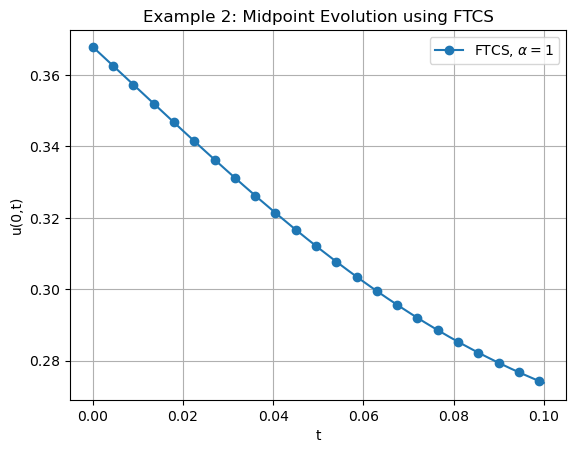

In [6]:
plt.figure()

plt.plot(
    time_values,
    midpoint_values,
    label=r"FTCS, $\alpha=1$",marker="o",markevery=18
)

plt.xlabel("t")
plt.ylabel("u(0,t)")

plt.title(
    "Example 2: Midpoint Evolution using FTCS"
)

plt.grid()
plt.legend()

plt.show()

In [7]:
left_slope = (
    -3*u[0]
    + 4*u[1]
    - u[2]
) / (2*dx)

right_slope = (
    3*u[-1]
    - 4*u[-2]
    + u[-3]
) / (2*dx)

print("Left boundary slope  =", left_slope)
print("Expected left slope  =", -1.0)

print("Right boundary slope =", right_slope)
print(
    "Expected right slope =",
    -1/np.exp(2)
)

Left boundary slope  = -1.0000000000000044
Expected left slope  = -1.0
Right boundary slope = -0.1353352832366127
Expected right slope = -0.1353352832366127


In [11]:



def reference_solution_example2(
    Nx_ref=1600,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5
):

    # Spatial grid
    x = np.linspace(-1.0, 1.0, Nx_ref + 1)
    dx = x[1] - x[0]

    # Initial condition
    u0 = np.exp(-(x + 1))

    # Only integrate the interior values
    u0_interior = u0[1:-1]


    def rhs(t, u_interior):

        # Reconstruct full solution
        u = np.empty(Nx_ref + 1)

        u[1:-1] = u_interior


        # ----------------------------------
        # Neumann boundary conditions
        # ----------------------------------

        # ux(-1,t) = -1
        u[0] = (
            4*u[1]
            - u[2]
            + 2*dx
        ) / 3


        # ux(1,t) = -1/e^2
        u[-1] = (
            4*u[-2]
            - u[-3]
            - 2*dx/np.exp(2)
        ) / 3


        # Second derivative at interior points
        u_xx = (
            u[2:]
            - 2*u[1:-1]
            + u[:-2]
        ) / dx**2


        # Nonlinear reaction
        reaction = (
            cs
            * u[1:-1]
            * (1-u[1:-1])
            * (u[1:-1]-a)
        )


        return (
            cd*u_xx
            + reaction
        )


    solution = solve_ivp(
        rhs,
        [0, t_final],
        u0_interior,
        method="BDF",
        rtol=1e-9,
        atol=1e-11
    )


    # Reconstruct final solution
    u_final = np.empty(Nx_ref + 1)

    u_final[1:-1] = solution.y[:, -1]


    # Apply Neumann BCs again
    u_final[0] = (
        4*u_final[1]
        - u_final[2]
        + 2*dx
    ) / 3

    u_final[-1] = (
        4*u_final[-2]
        - u_final[-3]
        - 2*dx/np.exp(2)
    ) / 3


    return x, u_final

In [12]:
def ftcs_final_example2(
    Nx,
    cd=1.0,
    cs=50.0,
    a=0.5,
    t_final=0.5,
    r_target=0.4
):

    x = np.linspace(-1.0, 1.0, Nx + 1)

    dx = x[1] - x[0]

    # Initial condition
    u = np.exp(-(x + 1))


    # Time step
    dt = r_target * dx**2 / cd

    Nt = int(np.ceil(t_final / dt))

    dt = t_final / Nt

    r = cd * dt / dx**2


    for n in range(Nt):

        u_new = u.copy()


        # Interior points
        for i in range(1, Nx):

            diffusion = (
                r
                * (
                    u[i+1]
                    - 2*u[i]
                    + u[i-1]
                )
            )

            reaction = (
                dt
                * cs
                * u[i]
                * (1-u[i])
                * (u[i]-a)
            )

            u_new[i] = (
                u[i]
                + diffusion
                + reaction
            )


        # Neumann boundaries

        u_new[0] = (
            4*u_new[1]
            - u_new[2]
            + 2*dx
        ) / 3

        u_new[-1] = (
            4*u_new[-2]
            - u_new[-3]
            - 2*dx/np.exp(2)
        ) / 3


        u = u_new


    return x, u

In [13]:
x_ref, u_ref = reference_solution_example2()

Nx_values = [5, 10, 15, 20, 25, 30, 40, 60, 80, 100, 120]

print("\nNx        Maximum absolute error")
print("--------------------------------")

for Nx in Nx_values:

    x_ftcs, u_ftcs = ftcs_final_example2(Nx)

    # Interpolate the fine reference solution
    # onto the FTCS grid
    u_reference_at_ftcs_points = np.interp(
        x_ftcs,
        x_ref,
        u_ref
    )

    # Maximum absolute error
    error = np.max(
        np.abs(
            u_ftcs
            - u_reference_at_ftcs_points
        )
    )

    print(
        f"{Nx:<10} {error:.10e}"
    )


Nx        Maximum absolute error
--------------------------------
5          2.3587402344e-01
10         6.8846378119e-02
15         3.4548236142e-02
20         2.1108510639e-02
25         1.4330791759e-02
30         1.0400797265e-02
40         6.2212809120e-03
60         2.9642464405e-03
80         1.7318844620e-03
100        1.1346849875e-03
120        8.0025764538e-04


### Error Analysis for Example 2

The maximum absolute error was calculated at $t=0.5$ by comparing the FTCS solution with a high-resolution numerical reference solution.

The results showed a clear decrease in error as the spatial grid was refined. For example, the error decreased from

$$
2.3587\times10^{-1}
$$

at

$$
N_x=5
$$

to

$$
8.0026\times10^{-4}
$$

at

$$
N_x=120.
$$

This shows that the FTCS method converges as the number of spatial grid points is increased.

The convergence rate also improved as the grid became finer. For example, comparing $N_x=40$ and $N_x=80$ gives an observed order of approximately

$$
p\approx1.84,
$$

while comparing $N_x=60$ and $N_x=120$ gives

$$
p\approx1.89.
$$

These values are approaching the expected second-order behaviour of the finite-difference approximation.

The result at $N_x=10$ was approximately

$$
6.88\times10^{-2},
$$

which is close to the value reported in Table 2 of the original paper. However, the FTCS errors continued to decrease as the grid was refined, while the errors reported in the paper remained approximately constant for larger values of $N_x$.

This difference is expected because the two studies use different numerical reference solutions. The original paper compares its Chebyshev/Laplace solution with Mathematica's `NDSolve`, while the FTCS method in this investigation is compared with a high-resolution Python reference solution.

Overall, the error analysis confirms that the FTCS method provides a convergent solution for Example 2 with Neumann boundary conditions.